<a href="https://colab.research.google.com/github/AliAFar-Me/brain-tumor-mri-streamlit/blob/main/AIxMed26_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#AIxMed26 — Project 2: Vision Transformers
##Classifying Brain Tumors from MRI Scans, Supervised vs. Self-Supervised ViTs

 Name: Ali Ahmad Farhat

 Dataset Name: Brain Tumor MRI Dataset

 Dataset Link: https://www.kaggle.com/datasets/masoudnickparvar/brain-tumor-mri-dataset

 Models Used:

*   Supervised: google/vit-base-patch16-224, microsoft/swin-tiny-patch4-window7-224
*    Self-Supervised: microsoft/rad-dino, facebook/vit-mae-base







## Streamlit Application
* **Live Streamlit App:** [https://brain-tumor-mri-app-wnxsj73nbqgprvktsgtkgn.streamlit.app/]
* **Hugging Face Model Hub:** [https://huggingface.co/AliAFar/brain-tumor-vit-best](https://huggingface.co/AliAFar/brain-tumor-vit-best)

---
## Step 0 — Importing the Libraries

In [ ]:
!pip install streamlit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 19.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 21.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [streamlit]


In [ ]:
import warnings
warnings.filterwarnings('ignore')

from tqdm.notebook import tqdm

import copy
import gc
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from datasets import load_dataset, DatasetDict, Dataset # Hugging Face datasets
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset

from transformers import (
    ViTModel,
    ViTImageProcessor,
    AutoModel,               # RAD-DINO loads as a Dinov2Model via AutoModel
    AutoImageProcessor,
)

from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    auc,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")

Using device: cuda


---
## Step 1: Loading the Dataset

In [ ]:
# 1. Download dataset using Kaggle's Python API
dataset_path = kagglehub.dataset_download("masoudnickparvar/brain-tumor-mri-dataset")
print(f"Dataset downloaded to: {dataset_path}")

# 2. Load into Hugging Face Datasets by specifying data_files or split mappings explicitly
# Since folder names are 'Training' and 'Testing', we define them explicitly
raw_dataset = load_dataset(
    "imagefolder",
    data_dir=dataset_path,
    data_files={
        "train": "Training/**/*",
        "test": "Testing/**/*"
    }
)

# 4. Assemble the final Hugging Face DatasetDict
hf_dataset = DatasetDict({
    "train": raw_dataset["train"],
    "test": raw_dataset["test"]
})

print(hf_dataset)

Using Colab cache for faster access to the 'brain-tumor-mri-dataset' dataset.
Dataset downloaded to: /kaggle/input/brain-tumor-mri-dataset


Resolving data files:   0%|          | 0/5600 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/1600 [00:00<?, ?it/s]

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['image', 'label'],
        num_rows: 5600
    })
    test: Dataset({
        features: ['image', 'label'],
        num_rows: 1600
    })
})


---
##Step 2: Preproccesing and EDA

In [ ]:
train_dataset = hf_dataset['train']
test_dataset  = hf_dataset['test']
Class_names = train_dataset.features['label'].names
NUM_CLASSES = len(Class_names)
print(f"Class names: {Class_names}")

Class names: ['glioma', 'meningioma', 'notumor', 'pituitary']


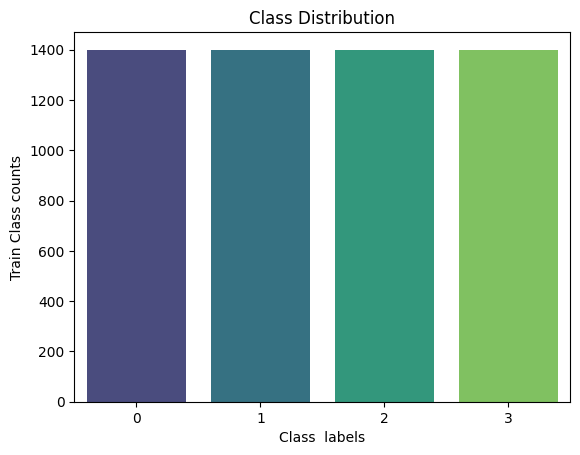

In [ ]:
labels = train_dataset['label']
ulabels,counts = np.unique(labels,return_counts=True)
#print(ulabels,counts)
sns.barplot(x=ulabels,y=counts,palette='viridis')
plt.title('Class Distribution')
plt.xlabel('Class  labels')
plt.ylabel('Train Class counts')
plt.show()

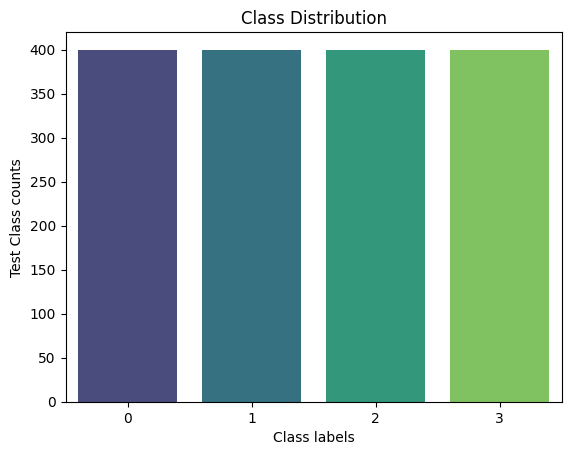

In [ ]:
labels_ts = test_dataset['label']
ulabels,counts = np.unique(labels_ts,return_counts=True)
#print(ulabels,counts)
sns.barplot(x=ulabels,y=counts,palette='viridis')
plt.title('Class Distribution')
plt.xlabel('Class labels')
plt.ylabel('Test Class counts')
plt.show()

---
### Step 1.1 — Split into Train / Validation / Test

In [ ]:
train_val_ds = hf_dataset['train'].train_test_split(test_size=0.2)
train_ds = train_val_ds['train']
val_ds = train_val_ds['test']
test_ds = hf_dataset['test']

print(f"Train : {len(train_ds):>6} scans  (~60%)")
print(f"Val   : {len(val_ds):>6} scans  (~20%)")
print(f"Test  : {len(test_ds):>6} scans  (~20%)")
print(f"Total : {len(train_ds)+len(val_ds)+len(test_ds):>6}")

Train :   4480 scans  (~60%)
Val   :   1120 scans  (~20%)
Test  :   1600 scans  (~20%)
Total :   7200


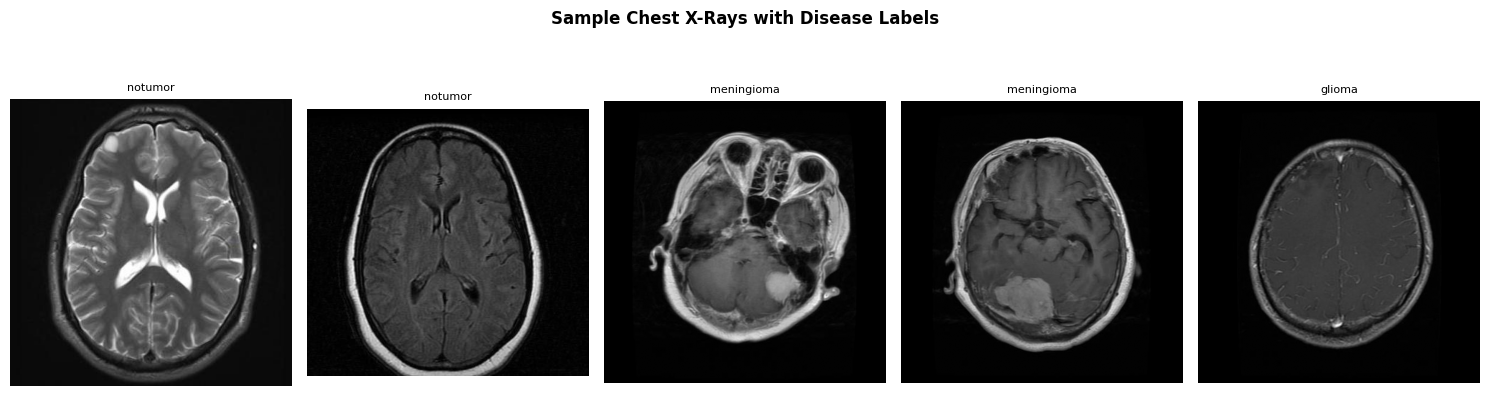

In [ ]:
def labels_to_names(i):
    return Class_names[i]

fig, axes = plt.subplots(1, 5, figsize=(15, 4.5))
for ax, row in zip(axes, train_ds.select(range(5))):
    ax.imshow(np.array(row['image']), cmap='gray')
    ax.set_title(labels_to_names(row['label']), fontsize=8)
    ax.axis('off')

plt.suptitle("Sample Chest X-Rays with Disease Labels", fontweight='bold') # Change the title its MRI
plt.tight_layout()
plt.show()

---
## Step 2 — PyTorch Dataset Wrapper

In [ ]:
class BrainTumorMRI_Wrapper(Dataset):
  def __init__(self,hf_dataset, num_class, processor=None):
    self.hf_dataset = hf_dataset
    self.num_class = num_class
    self.processor = processor

  def __len__(self):
    return len(self.hf_dataset)

  def __getitem__(self,idx):
    row = self.hf_dataset[idx]
    label = row['label']
    image = row['image'].convert("RGB")
    pixel_values = self.processor(image, return_tensors="pt")["pixel_values"][0]
    return pixel_values, label

---
## Step 3 — Load the Four Backbones (ViTs & RAD-DINO)

We load two encoders from `transformers`, both ViT-B backbones producing a **768-dim `CLS` embedding**:

| | Checkpoint | Loader | Processor |
|---|---|---|---|
| **Model A — ViT**      | `google/vit-base-patch16-224` | `ViTModel` | `ViTImageProcessor` |
| **Model B — ViT**      | `microsoft/swin-tiny-patch4-window7-224` | `ViTModel` | `ViTImageProcessor` |
| **Model C — ViT**      | `google/vit-base-patch16-224` | `AutoModel` (→ `MAE_Base`) | `AutoImageProcessor` |
| **Model D — RAD-DINO** | `microsoft/rad-dino`          | `AutoModel` (→ `Dinov2Model`) | `AutoImageProcessor` |

In [ ]:
# MODEL A
VIT_BASE = "google/vit-base-patch16-224"

print(f"Loading ViT_BASE backbone      : {VIT_BASE}")
vitbase_processor = ViTImageProcessor.from_pretrained(VIT_BASE)
vitbase_backbone  = ViTModel.from_pretrained(VIT_BASE)

Loading ViT_BASE backbone      : google/vit-base-patch16-224


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
# MODEL B
VIT_SWIN = "microsoft/swin-tiny-patch4-window7-224"

print(f"Loading VIT_SWIN backbone : {VIT_SWIN}")
vit_swin_processor = AutoImageProcessor.from_pretrained(VIT_SWIN)
vit_swin_backbone = AutoModel.from_pretrained(VIT_SWIN) # Use AutoModel

Loading VIT_SWIN backbone : microsoft/swin-tiny-patch4-window7-224


preprocessor_config.json:   0%|          | 0.00/255 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/71.8k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  113MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/219 [00:00<?, ?it/s]

[transformers] SwinModel LOAD REPORT from: microsoft/swin-tiny-patch4-window7-224
Key               | Status     |  | 
------------------+------------+--+-
classifier.bias   | UNEXPECTED |  | 
classifier.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [ ]:
# MODEL C
VIT_MAE_BASE= "facebook/vit-mae-base"

print(f"Loading VIT_MAE_BASE backbone : {VIT_MAE_BASE}")
vit_mae_processor = AutoImageProcessor.from_pretrained(VIT_MAE_BASE)
vit_mae_backbone = AutoModel.from_pretrained(VIT_MAE_BASE)

Loading VIT_MAE_BASE backbone : facebook/vit-mae-base


preprocessor_config.json:   0%|          | 0.00/217 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/676 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  448MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTMAEModel LOAD REPORT from: facebook/vit-mae-base
Key                                                                     | Status     |  | 
------------------------------------------------------------------------+------------+--+-
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.k_proj.weight | UNEXPECTED |  | 
decoder.decoder_norm.weight                                             | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.mlp.fc1.weight          | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.v_proj.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.layernorm_after.bias    | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.o_proj.weight | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.attention.o_proj.bias   | UNEXPECTED |  | 
decoder.decoder_layers.{0, 1, 2, 3, 4, 5, 6, 7}.mlp.fc1.bias            | UNEXPECTED |  | 
decoder.decoder_layers.

In [ ]:
# MODEL D
RADDINO_NAME = "microsoft/rad-dino"

print(f"Loading RAD-DINO backbone : {RADDINO_NAME}")
raddino_processor = AutoImageProcessor.from_pretrained(RADDINO_NAME)
raddino_backbone  = AutoModel.from_pretrained(RADDINO_NAME)

Loading RAD-DINO backbone : microsoft/rad-dino


preprocessor_config.json:   0%|          | 0.00/756 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/879 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

---
## Step 4 — Attach a Multi-Label Head & Freeze the Backbone

In [ ]:
class Classifier(nn.Module):
  def __init__(self,backbone,num_classes):
    super().__init__()
    self.backbone = backbone
    hidden = self.backbone.config.hidden_size
    self.head = nn.Linear(hidden,num_classes)

    for param in self.backbone.parameters():
      param.requires_grad = False
  def forward(self,X):
    logits = self.backbone(X)
    cls = logits.last_hidden_state[:,0]
    return self.head(cls)

In [ ]:
vit_base_cls = Classifier(vitbase_backbone,NUM_CLASSES)
vit_swin_cls = Classifier(vit_swin_backbone,NUM_CLASSES)
vit_mae_cls = Classifier(vit_mae_backbone,NUM_CLASSES)
raddino_cls = Classifier(raddino_backbone,NUM_CLASSES)

In [ ]:
vit_base_total     = sum(p.numel() for p in vit_base_cls.parameters())
vit_trainable = sum(p.numel() for p in vit_base_cls.parameters() if p.requires_grad)

vit_swin_total= sum(p.numel() for p in vit_swin_cls.parameters())
vit_swin_trainable = sum(p.numel() for p in vit_swin_cls.parameters() if p.requires_grad)

vit_mae_total= sum(p.numel() for p in vit_mae_cls.parameters())
vit_mae_trainable = sum(p.numel() for p in vit_mae_cls.parameters() if p.requires_grad)

raddion_total = sum(p.numel() for p in raddino_cls.parameters())
raddion_trainable = sum(p.numel() for p in raddino_cls.parameters() if p.requires_grad)

print(f"VIT | Trainable Parameters {vit_trainable} | Total Parameters {vit_base_total}")
print(f"RadDINO | Trainable Parameters {raddion_trainable} | Total Parameters {raddion_total}")
print(f"VIT-MAE | Trainable Parameters {vit_mae_trainable} | Total Parameters {vit_mae_total}")
print(f"VIT-SWIN | Trainable Parameters {vit_swin_trainable} | Total Parameters {vit_swin_total}")

VIT | Trainable Parameters 3076 | Total Parameters 86392324
RadDINO | Trainable Parameters 3076 | Total Parameters 86583556
VIT-MAE | Trainable Parameters 3076 | Total Parameters 85801732
VIT-SWIN | Trainable Parameters 3076 | Total Parameters 27522430


## Step 5 — DataLoaders

In [ ]:
# Model A
BATCH_SIZE = 128

vbase_train_ds = BrainTumorMRI_Wrapper(train_ds, NUM_CLASSES, processor=vitbase_processor)
vbase_val_ds = BrainTumorMRI_Wrapper(val_ds, NUM_CLASSES, processor=vitbase_processor)
vbase_test_ds = BrainTumorMRI_Wrapper(test_ds, NUM_CLASSES, processor=vitbase_processor)

vbase_train_dl = DataLoader(dataset=vbase_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
vbase_val_dl = DataLoader(dataset=vbase_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
vbase_test_dl = DataLoader(dataset=vbase_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
# Model B
swim_train_ds = BrainTumorMRI_Wrapper(train_ds, NUM_CLASSES, processor=vit_swin_processor)
swin_val_ds = BrainTumorMRI_Wrapper(val_ds, NUM_CLASSES, processor=vit_swin_processor)
swin_test_ds = BrainTumorMRI_Wrapper(test_ds, NUM_CLASSES, processor=vit_swin_processor)

swin_train_dl = DataLoader(dataset=swim_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
swin_val_dl = DataLoader(dataset=swin_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
swin_test_dl = DataLoader(dataset=swin_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
# Model C
mae_train_ds = BrainTumorMRI_Wrapper(train_ds, NUM_CLASSES, processor=vit_mae_processor)
mae_val_ds = BrainTumorMRI_Wrapper(val_ds, NUM_CLASSES, processor=vit_mae_processor)
mae_test_ds = BrainTumorMRI_Wrapper(test_ds, NUM_CLASSES, processor=vit_mae_processor)

mae_train_dl = DataLoader(dataset=mae_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
mae_val_dl = DataLoader(dataset=mae_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
mae_test_dl = DataLoader(dataset=mae_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

In [ ]:
# Model D
dino_train_ds = BrainTumorMRI_Wrapper(train_ds, NUM_CLASSES, processor=raddino_processor)
dino_val_ds = BrainTumorMRI_Wrapper(val_ds, NUM_CLASSES, processor=raddino_processor)
dino_test_ds = BrainTumorMRI_Wrapper(test_ds, NUM_CLASSES, processor=raddino_processor)

dino_train_dl = DataLoader(dataset=dino_train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
dino_val_dl = DataLoader(dataset=dino_val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
dino_test_dl = DataLoader(dataset=dino_test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

---
## Step 6 — Train the Head

In [ ]:
def train_head(model, train_loader, val_loader, epochs=10, lr=1e-3, device=device):
  model = model.to(device)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
  # GradScaler is used to scale losses for float16 mixed precision
  scaler = torch.amp.GradScaler('cuda')

  train_losses, val_f1s, val_aurocs = [], [], []
  best_f1, best_state = -1.0, None

  for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0
    for pixel_values, targets in (bar := tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]")):
      pixel_values, targets = pixel_values.to(device), targets.to(device)

      optimizer.zero_grad()

      # Run forward pass with mixed precision
      with torch.amp.autocast('cuda'):
        logits = model(pixel_values)
        loss = loss_fn(logits, targets)

      # Backward pass with scaled gradients
      scaler.scale(loss).backward()
      scaler.step(optimizer)
      scaler.update()

      epoch_loss += loss.item()
      bar.set_postfix({"loss": loss.item()})

    # Validation loop
    val_scores, val_targets = [], []
    model.eval()
    with torch.no_grad():
      for pixel_values, targets in (vbar := tqdm(val_loader, desc=f"Epoch {epoch+1}/{epochs} [Val]")):
        pixel_values = pixel_values.to(device)
        with torch.amp.autocast('cuda'):
          logits = model(pixel_values)
        # Force cast logits to float32 before softmax to avoid mixed-precision rounding errors
        probs = torch.softmax(logits.float(), dim=-1).cpu()
        val_scores.append(probs)
        val_targets.append(targets)

      val_scores = torch.cat(val_scores).numpy()
      # Re-normalize rows to guarantee that they sum up to exactly 1.0 for Scikit-Learn
      val_scores = val_scores / val_scores.sum(axis=1, keepdims=True)
      val_targets = torch.cat(val_targets).numpy()

    avg_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_loss)

    # Get predictions for F1-score
    val_preds = val_scores.argmax(axis=1)
    val_f1 = f1_score(val_targets, val_preds, average="macro")
    val_auroc = roc_auc_score(val_targets, val_scores, average="macro", multi_class="ovr")

    val_aurocs.append(val_auroc)
    val_f1s.append(val_f1)

    if val_f1 > best_f1:
       best_f1 = val_f1
       best_state = copy.deepcopy(model.state_dict())

    print(f"Epoch {epoch+1}: train loss={avg_loss:.4f} | val macro-AUROC={val_auroc:.4f} | val F1={val_f1:.4f}")

  if best_state is not None:
      model.load_state_dict(best_state)
      print(f"\nBest val macro-F1: {best_f1:.4f} (restored best weights)")

  return train_losses, val_aurocs, val_f1s

### 6.1 — Train Model A: ViT_base

In [ ]:
# Training Model A
print("=" * 60)
print("  Training head on  ViT_Base")
print("=" * 60)
device
torch.manual_seed(42)
torch.cuda.empty_cache()

# Run training
vbase_losses, vbase_val_aurocs, vbase_val_f1 = train_head(vit_base_cls, vbase_train_dl, vbase_val_dl, epochs=15, device=device)

  Training head on  ViT_Base


Epoch 1/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1: train loss=0.8563 | val macro-AUROC=0.9361 | val F1=0.7953


Epoch 2/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

...

Epoch 14/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 14: train loss=0.2274 | val macro-AUROC=0.9883 | val F1=0.9117


Epoch 15/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 15/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 15: train loss=0.2215 | val macro-AUROC=0.9886 | val F1=0.9065

Best val macro-F1: 0.9117 (restored best weights)


### 6.2 — Train Model B: ViT_swin

In [ ]:
# Training Model B
print("=" * 60)
print("  Training the head on Swin_ViT (with AMP & Offloading)")
print("=" * 60)
gc.collect()
torch.cuda.empty_cache()
torch.manual_seed(42)
swin_losses, swin_val_aurocs, swin_val_f1 = train_head(vit_swin_cls, swin_train_dl, swin_val_dl, epochs=15, device=device)

  Training the head on Swin_ViT (with AMP & Offloading)


Epoch 1/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1: train loss=1.2196 | val macro-AUROC=0.9054 | val F1=0.6499


Epoch 2/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

...

Epoch 14/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 14: train loss=0.4824 | val macro-AUROC=0.9692 | val F1=0.8562


Epoch 15/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 15/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 15: train loss=0.4735 | val macro-AUROC=0.9696 | val F1=0.8631

Best val macro-F1: 0.8631 (restored best weights)


### 6.3 — Train Model C: ViT_MAE

In [ ]:
# Training Model C

print("=" * 60)
print("  Training the head on  MAE_ViT")
print("=" * 60)
torch.manual_seed(42)
torch.cuda.empty_cache()

mae_losses, mae_val_aurocs, mae_val_f1 = train_head(vit_mae_cls, mae_train_dl, mae_val_dl, epochs=15, device=device)

  Training the head on  MAE_ViT


Epoch 1/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1: train loss=1.2944 | val macro-AUROC=0.8943 | val F1=0.6262


Epoch 2/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

...

Epoch 14/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 14: train loss=0.5840 | val macro-AUROC=0.9551 | val F1=0.8358


Epoch 15/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 15/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 15: train loss=0.5687 | val macro-AUROC=0.9526 | val F1=0.8259

Best val macro-F1: 0.8374 (restored best weights)


### 6.4 — Train Model D: Rad_Dina Model

In [ ]:
print("=" * 60)
print("  Training multi-label head on  RAD-DINO ")
print("=" * 60)
torch.manual_seed(42)
torch.cuda.empty_cache()

raddino_losses, raddino_val_aurocs, raddino_f1s = train_head(raddino_cls, dino_train_dl, dino_val_dl, epochs=15)

  Training multi-label head on  RAD-DINO 


Epoch 1/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 1/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1: train loss=1.0127 | val macro-AUROC=0.9313 | val F1=0.7683


Epoch 2/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

...

Epoch 14/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 14: train loss=0.3229 | val macro-AUROC=0.9785 | val F1=0.8761


Epoch 15/15 [Train]:   0%|          | 0/35 [00:00<?, ?it/s]

Epoch 15/15 [Val]:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 15: train loss=0.3169 | val macro-AUROC=0.9786 | val F1=0.8759

Best val macro-F1: 0.8791 (restored best weights)


## Step 7 — Compare Validation Curves

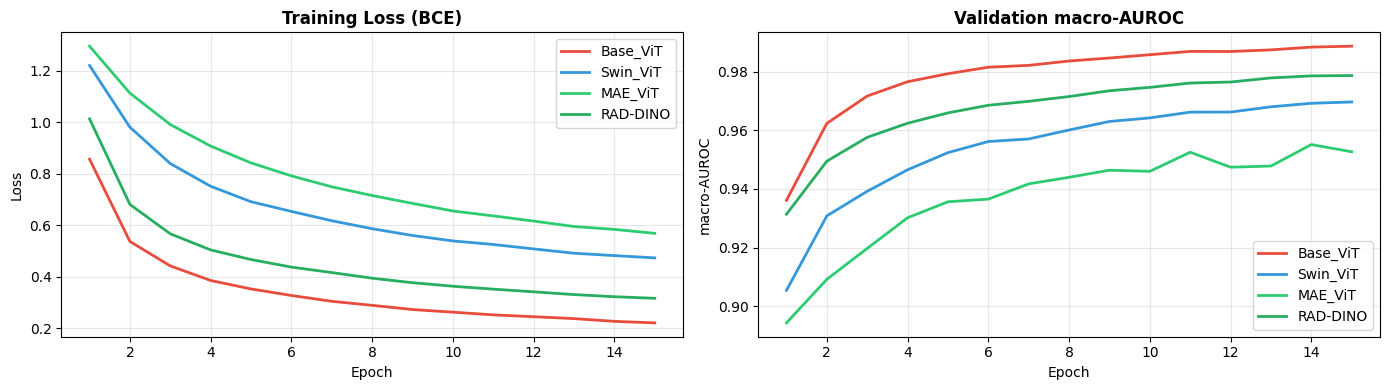

Best val macro-AUROC | ViT: 0.9886 | RAD-DINO: 0.9786 | Swin: 0.9696 | MAE: 0.9551


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
ep_v = range(1, len(vbase_losses) + 1)
ep_s = range(1, len(swin_losses) + 1)
ep_m = range(1, len(mae_losses) + 1)
ep_r = range(1, len(raddino_losses) + 1)

axes[0].plot(ep_v, vbase_losses,     label="Base_ViT",      color="#e74c3c", linewidth=2)
axes[0].plot(ep_s, swin_losses,     label="Swin_ViT",      color="#3498db", linewidth=2)
axes[0].plot(ep_m, mae_losses,      label="MAE_ViT",       color="#2ecc71", linewidth=2)
axes[0].plot(ep_r, raddino_losses, label="RAD-DINO", color="#27ae60", linewidth=2)
axes[0].set_title("Training Loss (BCE)", fontweight="bold")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(ep_v, vbase_val_aurocs,     label="Base_ViT",      color="#e74c3c", linewidth=2)
axes[1].plot(ep_s, swin_val_aurocs,     label="Swin_ViT",      color="#3498db", linewidth=2)
axes[1].plot(ep_m, mae_val_aurocs,      label="MAE_ViT",       color="#2ecc71", linewidth=2)
axes[1].plot(ep_r, raddino_val_aurocs, label="RAD-DINO", color="#27ae60", linewidth=2)
axes[1].set_title("Validation macro-AUROC", fontweight="bold")
axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("macro-AUROC")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Best val macro-AUROC | ViT: {max(vbase_val_aurocs):.4f} | RAD-DINO: {max(raddino_val_aurocs):.4f} | Swin: {max(swin_val_aurocs):.4f} | MAE: {max(mae_val_aurocs):.4f}")

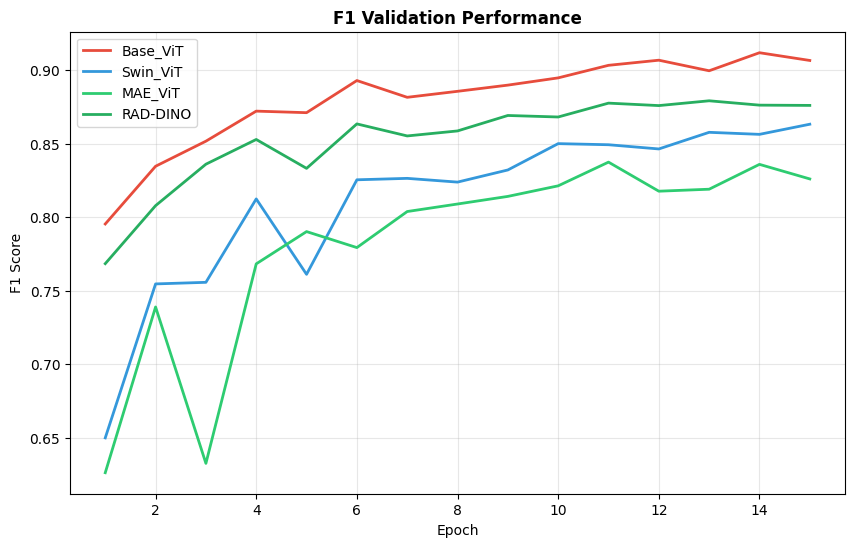

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(ep_v, vbase_val_f1,  label="Base_ViT",  color="#e74c3c", linewidth=2)
plt.plot(ep_s, swin_val_f1,   label="Swin_ViT",  color="#3498db", linewidth=2)
plt.plot(ep_m, mae_val_f1,    label="MAE_ViT",   color="#2ecc71", linewidth=2)
plt.plot(ep_r, raddino_f1s,   label="RAD-DINO",  color="#27ae60", linewidth=2)

plt.title("F1 Validation Performance", fontweight="bold")
plt.xlabel("Epoch")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

---
## Step  8  — Final Evaluation on the Test Set


## Step  8.1  — Final Evaluation on the Test Set for the VBase

In [ ]:
test_scores, test_targets = [], []
with torch.no_grad():
  for pixel_values, targets in (vbar := tqdm(vbase_test_dl, desc= f"[Test]")): #vbase_test_dl
      pixel_values = pixel_values.to(device)
      logits = vit_base_cls(pixel_values)

      probs = torch.softmax(logits.float(), dim=-1).cpu()
      test_scores.append(probs)
      test_targets.append(targets)

test_scores = torch.cat(test_scores).numpy()
test_targets = torch.cat(test_targets).numpy()

test_f1 = f1_score(test_targets, test_scores.argmax(axis=1), average="macro")
test_auroc = roc_auc_score(test_targets, test_scores, average="macro", multi_class="ovr")
print(f"Test AUC-ROC: {test_auroc:.3f} & Test F1_Score {test_f1:.3f}")

[Test]:   0%|          | 0/13 [00:00<?, ?it/s]

Test AUC-ROC: 0.972 & Test F1_Score 0.869


## Step  8.2  — Final Evaluation on the Test Set for the Rad_Dino

In [ ]:
test_scores_dina, test_targets_dino = [], []
with torch.no_grad():
  for pixel_values, targets in (vbar := tqdm(dino_test_dl, desc= f"[Test]")):
      pixel_values = pixel_values.to(device)
      logits = raddino_cls(pixel_values)


      probs = torch.softmax(logits.float(), dim=-1).cpu()
      test_scores_dina.append(probs)
      test_targets_dino.append(targets)

test_scores_dina = torch.cat(test_scores_dina).numpy()
test_targets_dino = torch.cat(test_targets_dino).numpy()

test_f1 = f1_score(test_targets_dino, test_scores_dina.argmax(axis=1), average="macro")
test_auroc = roc_auc_score(test_targets_dino, test_scores_dina, average="macro", multi_class="ovr")
print(f"Test AUC-ROC: {test_auroc:.3f} & Test F1_Score {test_f1:.3f}")

[Test]:   0%|          | 0/13 [00:00<?, ?it/s]

Test AUC-ROC: 0.943 & Test F1_Score 0.814


### 8.3 — Confusion Matrix for the VBase Model

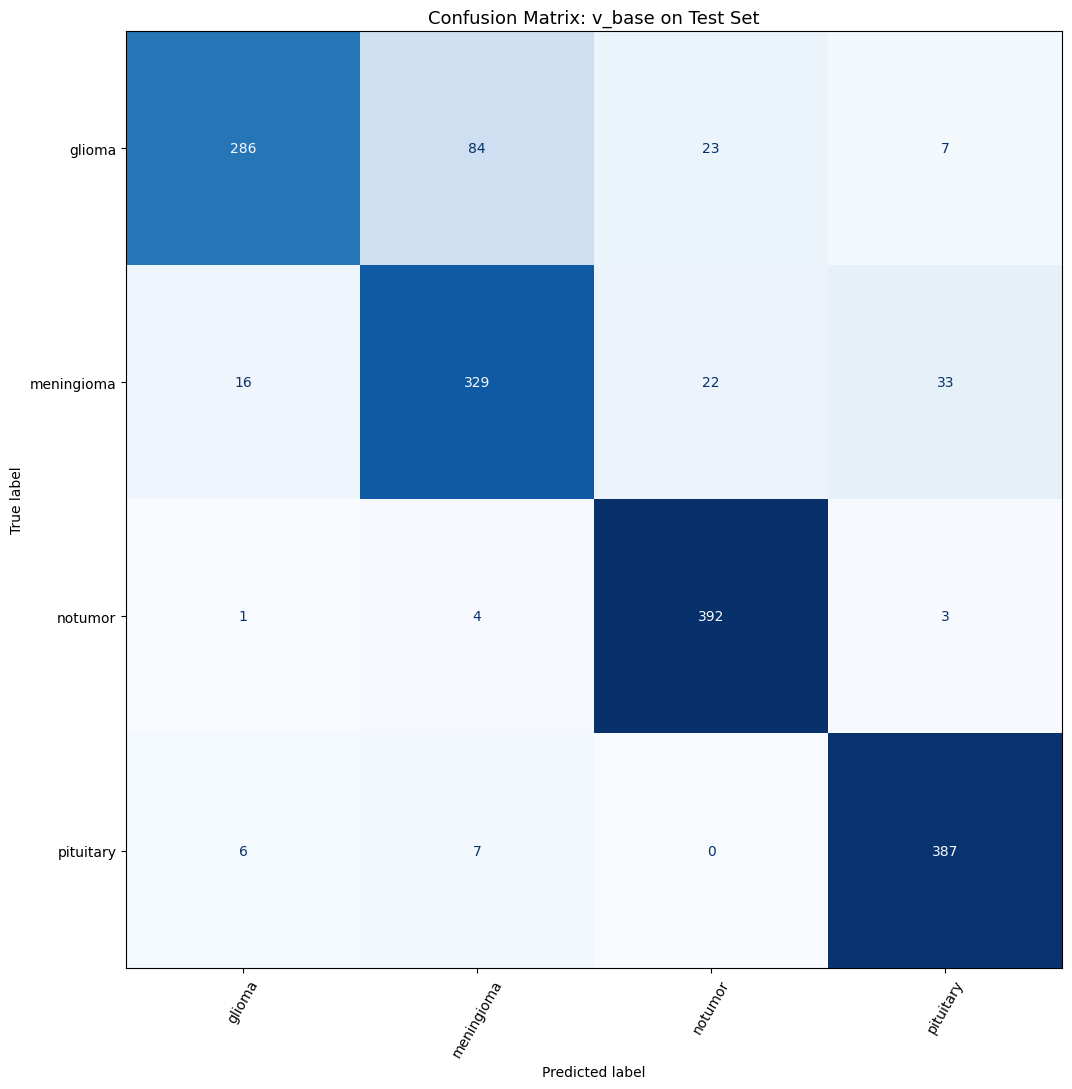


Per-class accuracy (recall):
  Class                 Correct    Total    Recall
  ------------------------------------------------
  glioma                    286      400     71.5%
  meningioma                329      400     82.2%
  notumor                   392      400     98.0%
  pituitary                 387      400     96.8%


In [ ]:
test_preds = test_scores.argmax(axis=1)
cm = confusion_matrix(test_targets, test_preds, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=Class_names).plot(
    cmap='Blues', ax=ax, colorbar=False, xticks_rotation=60
)
ax.set_title('Confusion Matrix: v_base on Test Set', fontsize=13)
plt.tight_layout()
plt.show()

print("\nPer-class accuracy (recall):")
print(f"  {'Class':<20}  {'Correct':>7}  {'Total':>7}  {'Recall':>8}")
print("  " + "-" * 48)
for i, name in enumerate(Class_names):
    row_total   = cm[i].sum()
    row_correct = cm[i, i]
    recall = row_correct / row_total * 100 if row_total else float('nan')
    print(f"  {name:<20}  {row_correct:>7}  {row_total:>7}  {recall:>7.1f}%")

### 8.4 — Confusion Matrix for the Rad_dino Model

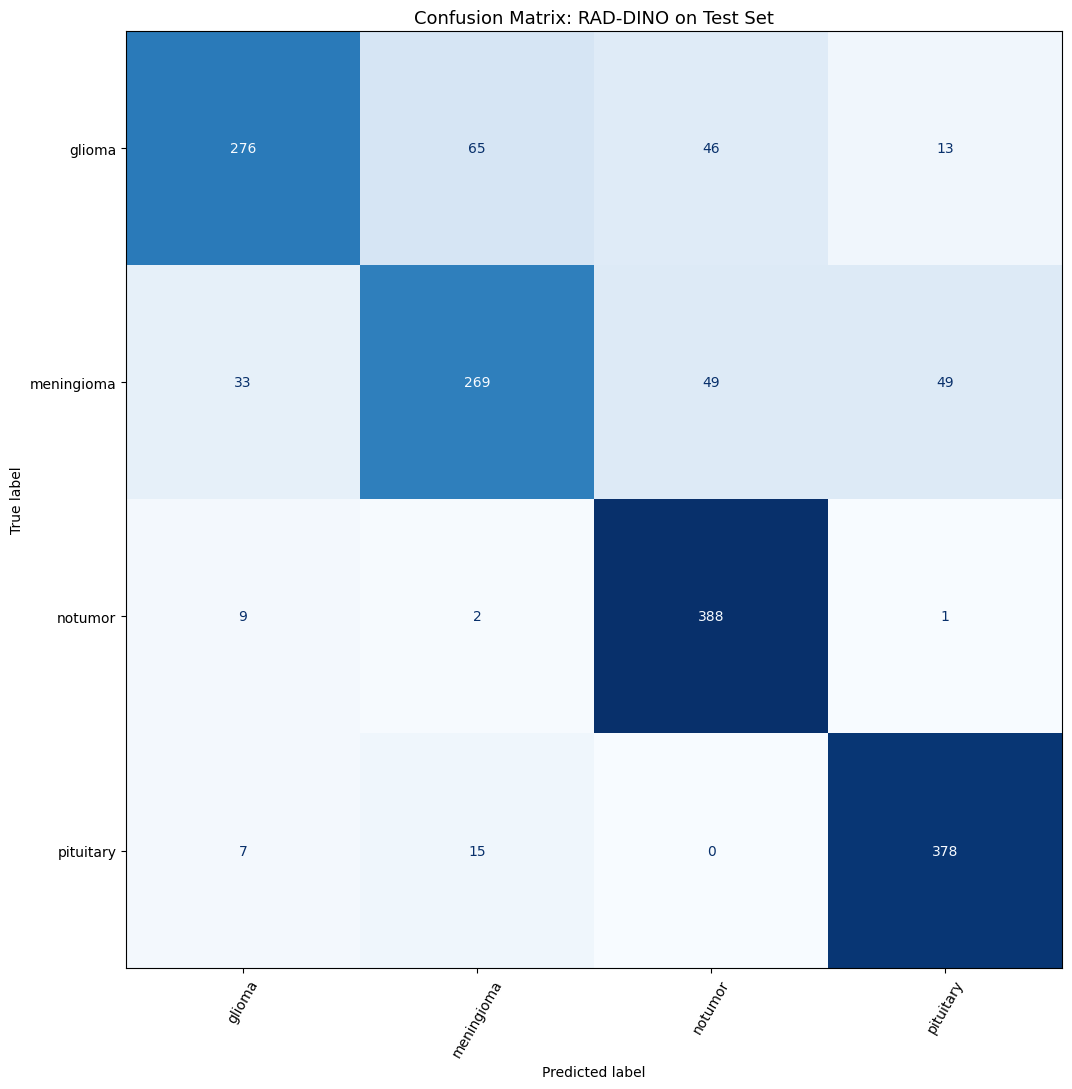


Per-class accuracy (recall):
  Class                 Correct    Total    Recall
  ------------------------------------------------
  glioma                    276      400     69.0%
  meningioma                269      400     67.2%
  notumor                   388      400     97.0%
  pituitary                 378      400     94.5%


In [ ]:
test_preds_dino = test_scores_dina.argmax(axis=1)
cm_R = confusion_matrix(test_targets_dino, test_preds_dino, labels=list(range(NUM_CLASSES)))

fig, ax = plt.subplots(figsize=(12, 11))
ConfusionMatrixDisplay(confusion_matrix=cm_R, display_labels=Class_names).plot(
    cmap='Blues', ax=ax, colorbar=False, xticks_rotation=60
)
ax.set_title('Confusion Matrix: RAD-DINO on Test Set', fontsize=13)
plt.tight_layout()
plt.show()

print("\nPer-class accuracy (recall):")
print(f"  {'Class':<20}  {'Correct':>7}  {'Total':>7}  {'Recall':>8}")
print("  " + "-" * 48)
for i, name in enumerate(Class_names):
    row_total_D   = cm_R[i].sum()
    row_correct_D = cm_R[i, i]
    recall_D = row_correct_D / row_total_D * 100 if row_total_D else float('nan')
    print(f"  {name:<20}  {row_correct_D:>7}  {row_total_D:>7}  {recall_D:>7.1f}%")

### 8.5 — Per-Class AUROC for the Best Model

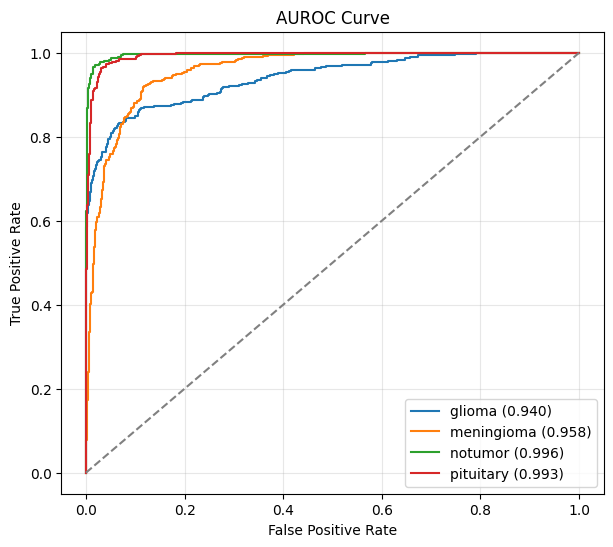

In [ ]:
plt.figure(figsize=(7, 6))
for c, l in enumerate(Class_names):

    fpr, tpr, _ = roc_curve(test_targets == c, test_scores[:, c])
    plt.plot(fpr, tpr, label=f"{l} ({auc(fpr, tpr):.3f})")

plt.plot([0, 1], [0, 1], "gray", ls="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("AUROC Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 9 — Pushing the  Best Model to Hugging Face (by the help of Gen AI)

In [ ]:
import torch
from huggingface_hub import HfApi
from google.colab import userdata

# 1. Retrieve the Hugging Face token securely
try:
    hf_token = userdata.get('HF_TOKEN')
except Exception as e:
    hf_token = None
    print("Warning: Could not retrieve 'HF_TOKEN' from secrets. Please make sure it is configured.")

# 2. Use ViT-Base as the base model backbone config
from transformers import ViTImageProcessor, ViTModel

backbone_id = "google/vit-base-patch16-224"
processor = ViTImageProcessor.from_pretrained(backbone_id)
backbone = ViTModel.from_pretrained(backbone_id)

# 3. Save processor and model configuration to Hugging Face
print("Pushing base model and configuration to Hugging Face repository...")
processor.push_to_hub("AliAFar/brain-tumor-vit-best", token=hf_token)
backbone.config.push_to_hub("AliAFar/brain-tumor-vit-best", token=hf_token)

# 4. Prepare and upload the head weights
best_model = vit_base_cls
best_model.cpu()

head_state_dict = {
    k: v for k, v in best_model.state_dict().items()
    if not k.startswith("backbone.")
}

weights_filename = "custom_classifier_head.pt"
torch.save(head_state_dict, weights_filename)

api = HfApi(token=hf_token)
api.upload_file(
    path_or_fileobj=weights_filename,
    path_in_repo=weights_filename,
    repo_id="AliAFar/brain-tumor-vit-best",
    repo_type="model"
)

print("Success! Both the ViT-Base backbone configuration and the custom classifier head weights have been uploaded to Hugging Face!")

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.bias     | UNEXPECTED | 
classifier.weight   | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Pushing base model and configuration to Hugging Face repository...


README.md:   0%|          | 0.00/5.17k [00:00<?, ?B/s]

No files have been modified since last commit. Skipping to prevent empty commit.


Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...custom_classifier_head.pt: 100%|##########| 14.4kB / 14.4kB            

Validating                    :           |   0%            

Success! Both the ViT-Base backbone configuration and the custom classifier head weights have been uploaded to Hugging Face!
